In [2]:
# Cell 1 — imports
from pathlib import Path

import geopandas as gpd
import pandas as pd
import numpy as np
import rasterio
import fiona
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, roc_auc_score, roc_curve, cohen_kappa_score
)

DATA_PROCESSED = Path("../data/processed")
DATA_RAW_INDONESIA = Path("../data/raw/cempaka_indonesia")

In [3]:
# Cell 2 — inline helper, no external module needed
def sample_raster_at_points(raster_path, points_gdf, band=1):
    with rasterio.open(raster_path) as src:
        pts = points_gdf.to_crs(src.crs) if points_gdf.crs != src.crs else points_gdf
        coords = [(geom.x, geom.y) for geom in pts.geometry]
        values = np.array([v[band - 1] for v in src.sample(coords)])
    return values

In [4]:
# Cell 3 — generate the two missing Sri Lanka terrain rasters (curvature)
import whitebox
wbt = whitebox.WhiteboxTools()
wbt.set_working_dir(str(DATA_PROCESSED.resolve()))
wbt.verbose = True

assert (DATA_PROCESSED / "dem_filled.tif").exists(), "dem_filled.tif missing — run notebook 02 first"

if not (DATA_PROCESSED / "plan_curvature.tif").exists():
    wbt.plan_curvature("dem_filled.tif", "plan_curvature.tif")
if not (DATA_PROCESSED / "profile_curvature.tif").exists():
    wbt.profile_curvature("dem_filled.tif", "profile_curvature.tif")

assert (DATA_PROCESSED / "plan_curvature.tif").exists()
assert (DATA_PROCESSED / "profile_curvature.tif").exists()
print("Curvature rasters ready")

Curvature rasters ready


In [5]:
# Cell 4 — reload Sri Lanka labels fresh, add elevation + curvature
labels_path = DATA_PROCESSED / "labels.parquet"
assert labels_path.exists(), "labels.parquet missing — run notebook 05 first"

sl_labels = gpd.read_parquet(labels_path)
print(f"Loaded {len(sl_labels)} Sri Lanka points")

sl_labels["elev"] = sample_raster_at_points(DATA_PROCESSED / "dem_utm.tif", sl_labels)
sl_labels["plan_curv"] = sample_raster_at_points(DATA_PROCESSED / "plan_curvature.tif", sl_labels)
sl_labels["profile_curv"] = sample_raster_at_points(DATA_PROCESSED / "profile_curvature.tif", sl_labels)

# also re-sample the original layers if not already present (safe to re-run)
sl_labels["slope"] = sample_raster_at_points(DATA_PROCESSED / "slope.tif", sl_labels)
sl_labels["aspect"] = sample_raster_at_points(DATA_PROCESSED / "aspect.tif", sl_labels)
sl_labels["twi"] = sample_raster_at_points(DATA_PROCESSED / "twi.tif", sl_labels)
sl_labels["spi"] = sample_raster_at_points(DATA_PROCESSED / "spi.tif", sl_labels)
sl_labels["dist_to_river"] = sample_raster_at_points(DATA_PROCESSED / "dist_to_river.tif", sl_labels)
sl_labels["dist_to_road"] = sample_raster_at_points(DATA_PROCESSED / "dist_to_road.tif", sl_labels)

print(sl_labels.isnull().sum())

Loaded 78 Sri Lanka points
geometry         0
label            0
source           0
adm2_name        0
adm2_pcode       0
elev             0
plan_curv        0
profile_curv     0
slope            0
aspect           0
twi              0
spi              0
dist_to_river    0
dist_to_road     0
dtype: int64


In [6]:
# Cell 5 — reload Indonesia dataset, check its actual curvature/elevation column names
indonesia_path = DATA_PROCESSED / "training_table_indonesia.parquet"
assert indonesia_path.exists(), "training_table_indonesia.parquet missing — run the Indonesia notebook first"

id_data = gpd.read_parquet(indonesia_path)
print("Indonesia columns:", id_data.columns.tolist())

Indonesia columns: ['lslpts', 'X', 'Y', 'geometry', 'label', 'source', 'aspect', 'distriv', 'distroad', 'elev', 'geologi', 'landuse', 'planc', 'profc', 'slope', 'spi', 'twi']


In [10]:
# Cell 6 — define the shared feature mapping explicitly (adjust right-hand names
# to match whatever Cell 5 actually printed for the Indonesia columns)
column_map = {
    # sri_lanka_name : indonesia_name
    "slope": "slope",   # <- fix once you see real Indonesia column names
    "aspect": "aspect",
    "twi": "twi",
    "spi": "spi",
    "dist_to_river": "distriv",
    "dist_to_road": "distroad",
    "elev": "elev",
    "plan_curv": "planc",
    "profile_curv": "profc",
}
print("Review this mapping against Cell 5's printed columns before continuing")

Review this mapping against Cell 5's printed columns before continuing


In [11]:
shared_sl_cols = list(column_map.keys())
shared_id_cols = list(column_map.values())

sl_features = sl_labels[shared_sl_cols + ["label"]].copy()

id_features = id_data[shared_id_cols + ["label"]].copy()
id_features.columns = shared_sl_cols + ["label"]

print(f"Sri Lanka: {sl_features.shape}, Indonesia: {id_features.shape}")
sl_features.head()

Sri Lanka: (78, 10), Indonesia: (1486, 10)


,slope,aspect,twi,spi,dist_to_river,dist_to_road,elev,plan_curv,profile_curv,label
0,8.794240,9.317299,1.866234,0.154705,253.139816,30.697712,1768.088623,0.025243,-0.000171,1
1,6.548500,217.219971,3.774061,0.573966,0.000000,61.395424,750.929077,0.003153,-0.002880,1
2,14.880496,267.809479,3.404773,2.125720,43.413120,86.826241,1011.710144,0.002502,-0.002175,1
3,6.143241,205.529968,2.922179,0.215265,43.413120,92.093132,25.290115,-0.003375,-0.000577,1
4,28.810682,161.704666,4.235428,20.899904,0.000000,110.682175,1048.303345,-0.003051,-0.001493,1


In [12]:
print("Slope — Indonesia:", id_data["slope"].describe())
print("Slope — Sri Lanka:", sl_labels["slope"].describe())
print("\nElevation — Indonesia:", id_data["elev"].describe())
print("Elevation — Sri Lanka:", sl_labels["elev"].describe())

Slope — Indonesia: count    1486.000000
mean       18.905046
std         8.970053
min         0.600000
25%        12.025000
50%        18.900000
75%        25.675001
max        46.000000
Name: slope, dtype: float64
Slope — Sri Lanka: count    78.000000
mean     14.534801
std      10.106173
min       0.001270
25%       8.037387
50%      12.779038
75%      20.378850
max      54.127697
Name: slope, dtype: float64

Elevation — Indonesia: count    1486.000000
mean      422.172852
std       268.424316
min        -5.400000
25%       209.550003
50%       374.949997
75%       604.100021
max      1163.099976
Name: elev, dtype: float64
Elevation — Sri Lanka: count      78.000000
mean      680.998718
std       556.510010
min        13.458694
25%       257.632767
50%       517.201447
75%      1000.122040
max      2371.135986
Name: elev, dtype: float64


In [13]:
# Cell 8 — train on Indonesia (the large, real dataset), test held-out Indonesia split
id_features = id_features.dropna()
X = id_features.drop(columns="label")
y = id_features["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

clf = RandomForestClassifier(
    n_estimators=200, criterion="entropy", max_depth=20,
    min_samples_split=4, min_samples_leaf=1, max_features="sqrt",
    class_weight="balanced", random_state=42, oob_score=True, n_jobs=-1,
)
clf.fit(X_train, y_train)
print(f"OOB score: {clf.oob_score_:.4f}")

OOB score: 0.6865


In [14]:
# Cell 9 — evaluate on held-out Indonesia data
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"Accuracy:    {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Sensitivity: {tp/(tp+fn)*100:.2f}%")
print(f"Specificity: {tn/(tn+fp)*100:.2f}%")
print(f"Kappa:       {cohen_kappa_score(y_test, y_pred):.4f}")
print(f"AUC:         {roc_auc_score(y_test, y_proba):.4f}")

Accuracy:    66.14%
Sensitivity: 66.37%
Specificity: 65.92%
Kappa:       0.3229
AUC:         0.7154


In [15]:
# Cell 10 — TRANSFER: apply the Indonesia-trained model to Sri Lanka's real points
sl_features_clean = sl_features.dropna()
X_sl = sl_features_clean.drop(columns="label")
y_sl_true = sl_features_clean["label"]

sl_pred = clf.predict(X_sl)
sl_proba = clf.predict_proba(X_sl)[:, 1]

print(f"Sri Lanka points evaluated: {len(X_sl)}")
print(f"Predicted positive: {sl_pred.sum()}, Actual positive: {y_sl_true.sum()}")
if y_sl_true.nunique() > 1:
    print(f"Transfer AUC on Sri Lanka: {roc_auc_score(y_sl_true, sl_proba):.4f}")

Sri Lanka points evaluated: 78
Predicted positive: 23, Actual positive: 39
Transfer AUC on Sri Lanka: 0.6279


In [16]:
from xgboost import XGBClassifier

xgb_clf = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    scale_pos_weight=(y_train==0).sum()/(y_train==1).sum(),
    random_state=42, eval_metric="logloss", n_jobs=-1,
)
xgb_clf.fit(X_train, y_train)
xgb_proba = xgb_clf.predict_proba(X_test)[:, 1]
xgb_pred = xgb_clf.predict(X_test)

print(f"XGBoost AUC: {roc_auc_score(y_test, xgb_proba):.4f}")
print(f"XGBoost Kappa: {cohen_kappa_score(y_test, xgb_pred):.4f}")

XGBoost AUC: 0.7045
XGBoost Kappa: 0.2915


In [17]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [10, 15, 20, 25, None],
    "min_samples_split": [2, 4, 6],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
}

search = RandomizedSearchCV(
    RandomForestClassifier(criterion="entropy", class_weight="balanced", random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=20,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
best_clf = search.best_estimator_

best_proba = best_clf.predict_proba(X_test)[:, 1]
best_pred = best_clf.predict(X_test)
print(f"Tuned RF AUC: {roc_auc_score(y_test, best_proba):.4f}")
print(f"Tuned RF Kappa: {cohen_kappa_score(y_test, best_pred):.4f}")

Best params: {'n_estimators': 300, 'min_samples_split': 4, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': None}
Tuned RF AUC: 0.7227
Tuned RF Kappa: 0.3453


In [18]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# SVM needs scaled features — unlike tree-based models, distance-based methods are sensitive to feature scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_clf = SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42)
svm_clf.fit(X_train_scaled, y_train)

svm_proba = svm_clf.predict_proba(X_test_scaled)[:, 1]
svm_pred = svm_clf.predict(X_test_scaled)

print(f"SVM AUC: {roc_auc_score(y_test, svm_proba):.4f}")
print(f"SVM Kappa: {cohen_kappa_score(y_test, svm_pred):.4f}")

SVM AUC: 0.7096
SVM Kappa: 0.3587


In [19]:
from sklearn.neural_network import MLPClassifier

mlp_clf = MLPClassifier(hidden_layer_sizes=(32,16), max_iter=500, random_state=42)
mlp_clf.fit(X_train_scaled, y_train)

mlp_proba = mlp_clf.predict_proba(X_test_scaled)[:, 1]
mlp_pred = mlp_clf.predict(X_test_scaled)

print(f"ANN AUC: {roc_auc_score(y_test, mlp_proba):.4f}")
print(f"ANN Kappa: {cohen_kappa_score(y_test, mlp_pred):.4f}")

ANN AUC: 0.6888
ANN Kappa: 0.3004


C:\Users\PCC\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [20]:
# combine predictions from models you've already trained tonight
rf_proba = best_clf.predict_proba(X_test)[:, 1]
xgb_proba = xgb_clf.predict_proba(X_test)[:, 1]
svm_proba = svm_clf.predict_proba(X_test_scaled)[:, 1]

ensemble_proba = (rf_proba + xgb_proba + svm_proba) / 3
ensemble_pred = (ensemble_proba >= 0.5).astype(int)

print(f"Ensemble AUC: {roc_auc_score(y_test, ensemble_proba):.4f}")
print(f"Ensemble Kappa: {cohen_kappa_score(y_test, ensemble_pred):.4f}")

Ensemble AUC: 0.7213
Ensemble Kappa: 0.3408


### Frequency Ratio–Random Forest hybrid (FR-RF)

In [21]:
def compute_fr_lookup(df, feature_col, label_col="label", n_bins=5):
    """Bin a continuous feature and compute Frequency Ratio for each bin,
    using only the training set to avoid leaking test data into the transform."""
    df = df.copy()
    df["_bin"] = pd.cut(df[feature_col], bins=n_bins, labels=False, duplicates="drop")

    total_pos = (df[label_col] == 1).sum()
    total_n = len(df)

    fr_lookup = {}
    bin_edges = pd.cut(df[feature_col], bins=n_bins, duplicates="drop").cat.categories

    for b in sorted(df["_bin"].dropna().unique()):
        group = df[df["_bin"] == b]
        class_pos = (group[label_col] == 1).sum()
        class_n = len(group)
        numerator = class_pos / total_pos if total_pos else 0
        denominator = class_n / total_n if total_n else 1
        fr = numerator / denominator if denominator else 0
        fr_lookup[b] = fr

    return fr_lookup, bin_edges

def apply_fr_transform(df, feature_col, fr_lookup, bin_edges, n_bins=5):
    """Apply a previously-fit FR lookup to any dataset (train or test)."""
    bins = pd.cut(df[feature_col], bins=bin_edges.union([bin_edges[0].left, bin_edges[-1].right]) if False else n_bins, labels=False, duplicates="drop")
    return bins.map(fr_lookup).fillna(np.mean(list(fr_lookup.values())))

In [22]:
def fr_transform_column(train_df, test_df, feature_col, label_col="label", n_bins=5):
    """Fit FR bins on train, apply identical bins to both train and test."""
    _, edges = pd.cut(train_df[feature_col], bins=n_bins, retbins=True, duplicates="drop")
    train_bins = pd.cut(train_df[feature_col], bins=edges, labels=False, include_lowest=True)

    total_pos = (train_df[label_col] == 1).sum()
    total_n = len(train_df)
    fr_lookup = {}
    for b in sorted(train_bins.dropna().unique()):
        mask = train_bins == b
        class_pos = (train_df.loc[mask, label_col] == 1).sum()
        class_n = mask.sum()
        num = class_pos / total_pos if total_pos else 0
        den = class_n / total_n if total_n else 1
        fr_lookup[b] = num / den if den else 1.0

    test_bins = pd.cut(test_df[feature_col], bins=edges, labels=False, include_lowest=True)
    train_fr = train_bins.map(fr_lookup).fillna(1.0)
    test_fr = test_bins.map(fr_lookup).fillna(1.0)
    return train_fr, test_fr

In [23]:
train_full = X_train.copy()
train_full["label"] = y_train.values
test_full = X_test.copy()
test_full["label"] = y_test.values

X_train_fr = pd.DataFrame(index=X_train.index)
X_test_fr = pd.DataFrame(index=X_test.index)

for col in X_train.columns:
    tr_fr, te_fr = fr_transform_column(train_full, test_full, col)
    X_train_fr[col] = tr_fr.values
    X_test_fr[col] = te_fr.values

print(X_train_fr.describe())

             slope       aspect          twi          spi  dist_to_river  \
count  1040.000000  1040.000000  1040.000000  1040.000000    1040.000000   
mean      1.000000     1.000000     1.000000     1.000000       1.000000   
std       0.325397     0.250845     0.157397     0.160766       0.170459   
min       0.438503     0.632124     0.000000     0.723618       0.000000   
25%       0.860681     0.786885     1.053118     1.049682       1.030785   
50%       1.266272     0.979381     1.053118     1.049682       1.030785   
75%       1.273256     1.164659     1.053118     1.049682       1.030785   
max       1.647059     1.330317     1.053118     1.533333       1.030785   

       dist_to_road         elev    plan_curv  profile_curv  
count   1040.000000  1040.000000  1040.000000   1040.000000  
mean       1.000000     1.000000     1.000000      1.000000  
std        0.053831     0.112927     0.158495      0.110616  
min        0.000000     0.860335     0.333333      0.000000  
25%  

In [24]:
fr_rf = RandomForestClassifier(
    n_estimators=300, min_samples_split=4, min_samples_leaf=4,
    max_features="log2", max_depth=None,
    class_weight="balanced", random_state=42, n_jobs=-1,
)
fr_rf.fit(X_train_fr, y_train)

fr_proba = fr_rf.predict_proba(X_test_fr)[:, 1]
fr_pred = fr_rf.predict(X_test_fr)

print(f"FR-RF Hybrid AUC: {roc_auc_score(y_test, fr_proba):.4f}")
print(f"FR-RF Hybrid Kappa: {cohen_kappa_score(y_test, fr_pred):.4f}")

FR-RF Hybrid AUC: 0.7340
FR-RF Hybrid Kappa: 0.3318


### LightGBM

In [25]:
# pip install lightgbm --quiet   (run once if not installed)
from lightgbm import LGBMClassifier

lgb_clf = LGBMClassifier(
    n_estimators=300, max_depth=-1, learning_rate=0.05,
    class_weight="balanced", random_state=42, verbose=-1,
)
lgb_clf.fit(X_train, y_train)

lgb_proba = lgb_clf.predict_proba(X_test)[:, 1]
lgb_pred = lgb_clf.predict(X_test)

print(f"LightGBM AUC: {roc_auc_score(y_test, lgb_proba):.4f}")
print(f"LightGBM Kappa: {cohen_kappa_score(y_test, lgb_pred):.4f}")

LightGBM AUC: 0.7017
LightGBM Kappa: 0.3184


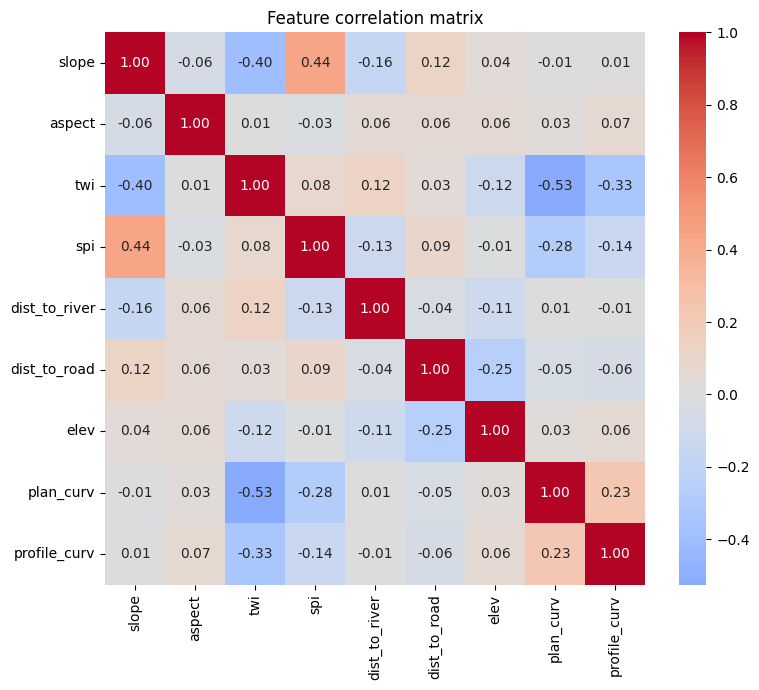

In [26]:
import seaborn as sns  # pip install seaborn if needed

feature_cols = ["slope", "aspect", "twi", "spi", "dist_to_river", "dist_to_road", "elev", "plan_curv", "profile_curv"]
corr = X_train[feature_cols].corr()

fig, ax = plt.subplots(figsize=(8,7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Feature correlation matrix")
plt.tight_layout()
plt.show()

In [28]:
! pip install optuna --quiet
import optuna
from sklearn.model_selection import cross_val_score

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "max_depth": trial.suggest_int("max_depth", 5, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2"]),
    }
    clf = RandomForestClassifier(**params, class_weight="balanced", random_state=42, n_jobs=-1)
    scores = cross_val_score(clf, X_train, y_train, cv=5, scoring="roc_auc")
    return scores.mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50, show_progress_bar=True)

print("Best AUC (CV):", study.best_value)
print("Best params:", study.best_params)

best_clf = RandomForestClassifier(**study.best_params, class_weight="balanced", random_state=42, n_jobs=-1)
best_clf.fit(X_train, y_train)


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\PCC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
[I 2026-08-09 09:26:25,019] A new study created in memory with name: no-name-b9fc2f2a-ed5a-41ea-8925-874f86b6bda7


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-08-09 09:26:26,388] Trial 0 finished with value: 0.7461908284023668 and parameters: {'n_estimators': 179, 'max_depth': 15, 'min_samples_split': 9, 'min_samples_leaf': 2, 'max_features': 'log2'}. Best is trial 0 with value: 0.7461908284023668.
[I 2026-08-09 09:26:27,608] Trial 1 finished with value: 0.7485207100591715 and parameters: {'n_estimators': 163, 'max_depth': 19, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 'sqrt'}. Best is trial 1 with value: 0.7485207100591715.
[I 2026-08-09 09:26:31,103] Trial 2 finished with value: 0.7502218934911242 and parameters: {'n_estimators': 383, 'max_depth': 17, 'min_samples_split': 6, 'min_samples_leaf': 6, 'max_features': 'sqrt'}. Best is trial 2 with value: 0.7502218934911242.
[I 2026-08-09 09:26:37,688] Trial 3 finished with value: 0.7486131656804733 and parameters: {'n_estimators': 313, 'max_depth': 20, 'min_samples_split': 3, 'min_samples_leaf': 7, 'max_features': 'sqrt'}. Best is trial 2 with value: 0.75022189349112

RandomForestClassifier(class_weight='balanced', max_depth=9,
                       max_features='log2', min_samples_leaf=5,
                       min_samples_split=10, n_estimators=478, n_jobs=-1,
                       random_state=42)

In [29]:
def woe_transform_column(train_df, test_df, feature_col, label_col="label", n_bins=5, epsilon=0.5):
    """Weight of Evidence transform, fit on train, applied identically to test.
    epsilon = small constant (Laplace-style smoothing) to avoid log(0) in sparse bins."""
    _, edges = pd.cut(train_df[feature_col], bins=n_bins, retbins=True, duplicates="drop")
    train_bins = pd.cut(train_df[feature_col], bins=edges, labels=False, include_lowest=True)

    total_pos = (train_df[label_col] == 1).sum()
    total_neg = (train_df[label_col] == 0).sum()

    woe_lookup = {}
    for b in sorted(train_bins.dropna().unique()):
        mask = train_bins == b
        pos = (train_df.loc[mask, label_col] == 1).sum()
        neg = (train_df.loc[mask, label_col] == 0).sum()

        pct_pos = (pos + epsilon) / (total_pos + epsilon)
        pct_neg = (neg + epsilon) / (total_neg + epsilon)
        woe_lookup[b] = np.log(pct_pos / pct_neg)

    test_bins = pd.cut(test_df[feature_col], bins=edges, labels=False, include_lowest=True)
    train_woe = train_bins.map(woe_lookup).fillna(0.0)
    test_woe = test_bins.map(woe_lookup).fillna(0.0)
    return train_woe, test_woe

In [30]:
X_train_woe = pd.DataFrame(index=X_train.index)
X_test_woe = pd.DataFrame(index=X_test.index)

for col in X_train.columns:
    tr_woe, te_woe = woe_transform_column(train_full, test_full, col)
    X_train_woe[col] = tr_woe.values
    X_test_woe[col] = te_woe.values

woe_rf = RandomForestClassifier(**study.best_params, class_weight="balanced", random_state=42, n_jobs=-1)
woe_rf.fit(X_train_woe, y_train)

woe_proba = woe_rf.predict_proba(X_test_woe)[:, 1]
woe_pred = woe_rf.predict(X_test_woe)

print(f"WoE-RF Hybrid AUC: {roc_auc_score(y_test, woe_proba):.4f}")
print(f"WoE-RF Hybrid Kappa: {cohen_kappa_score(y_test, woe_pred):.4f}")

WoE-RF Hybrid AUC: 0.7371
WoE-RF Hybrid Kappa: 0.3498


In [33]:
X_train_woe["slope_x_twi"] = X_train_woe["slope"] * X_train_woe["twi"]
X_test_woe["slope_x_twi"] = X_test_woe["slope"] * X_test_woe["twi"]

X_train_woe["slope_x_dist_road"] = X_train_woe["slope"] * X_train_woe["dist_to_road"]
X_test_woe["slope_x_dist_road"] = X_test_woe["slope"] * X_test_woe["dist_to_road"]

In [34]:
X_train_woe = pd.DataFrame(index=X_train.index)
X_test_woe = pd.DataFrame(index=X_test.index)

for col in X_train.columns:
    tr_woe, te_woe = woe_transform_column(train_full, test_full, col)
    X_train_woe[col] = tr_woe.values
    X_test_woe[col] = te_woe.values

woe_rf = RandomForestClassifier(**study.best_params, class_weight="balanced", random_state=42, n_jobs=-1)
woe_rf.fit(X_train_woe, y_train)

woe_proba = woe_rf.predict_proba(X_test_woe)[:, 1]
woe_pred = woe_rf.predict(X_test_woe)

print(f"WoE-RF Hybrid AUC: {roc_auc_score(y_test, woe_proba):.4f}")
print(f"WoE-RF Hybrid Kappa: {cohen_kappa_score(y_test, woe_pred):.4f}")

WoE-RF Hybrid AUC: 0.7371
WoE-RF Hybrid Kappa: 0.3498
